### Top Rows

In [312]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
file_path = "results-filtered.xlsx"
# df = pd.read_excel(file_path, sheet_name="kPEX")
df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3 v4".split()
versions="v0 v1 v2 v3".split()
branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2972182339.py:41: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

In [331]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1, 2, 3] for b in "S R P".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v0-R-mkp,v0-P-mkp,v1-S-mkp,v1-R-mkp,v1-P-mkp,v2-S-mkp,v2-R-mkp,v2-P-mkp,v3-S-mkp,v3-R-mkp,v3-P-mkp,dataset,k,v1-S-total
3,17,17,17,17,17,17,18,1800,1800,18,1800,1800,130bit,10,2.1
9,15,15,15,15,15,15,16,16,1800,16,16,1800,145bit,9,42.2
10,17,17,17,17,17,17,18,1800,1800,18,1800,1800,145bit,10,17.5
28,7,7,7,9,9,9,9,9,9,9,9,9,3D_51448_3D,3,1.3
31,13,13,13,15,15,15,15,15,15,15,15,15,3D_51448_3D,8,1.7
34,12,12,12,14,14,14,14,14,14,14,14,14,3Dspectralwave2,3,1.3
41,32,32,32,32,32,32,1800,36,36,1800,36,36,3Dspectralwave2,20,3.6
43,12,12,12,13,13,13,13,13,13,13,13,13,3Dspectralwave,3,1.3
55,24,24,24,26,26,26,26,26,26,26,26,26,3dtube,6,15.3
60,38,38,38,39,39,39,39,39,39,39,39,39,3dtube,15,74.6


np.int64(1217)

### Varying Ratio Threshold


=== Threshold 1.5 Analysis ===
v0-S-total wins: 735
v2-S-total wins: 306

--- Weaker side: v2-S-total ---


,dataset,k,v0-S-total,v2-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
3168,smt,20,1800.0,829.1,2.17x,0.4,0.8,3.8,1.3,4.2,2.1,,,1800.0,829.1,260.5,67.1,12.6,11.2
3637,std1_Jac2,15,1800.0,618.4,2.91x,0.4,0.6,4.7,0.4,5.1,0.9,,,1800.0,618.4,171.2,83.7,1800.0,1800.0
3656,sx-stackoverflow,5,844.2,514.2,1.64x,6.6,7.3,0.2,0.1,6.8,7.4,,,844.2,514.2,1800.0,1713.6,6.7,8.9
4201,wikiconflict,7,677.6,371.1,1.83x,0.6,0.6,0.2,0.1,0.8,0.7,,,677.6,371.1,156.5,250.9,1.9,2.6
3617,srb1,15,536.7,343.8,1.56x,0.1,0.2,1.7,0.5,1.9,0.7,,,536.7,343.8,59.0,54.3,16.5,14.3
1844,karted,5,474.5,256.7,1.85x,0.3,0.4,252.1,24.5,252.4,25.0,,,474.5,256.7,473.7,261.1,474.9,238.8
1843,karted,4,373.6,219.6,1.70x,0.3,0.5,150.7,22.4,151.0,22.9,,,373.6,219.6,373.6,223.1,373.7,205.9
3245,socfb-BC17,15,473.4,215.8,2.19x,0.1,0.1,0.0,0.0,0.2,0.1,,,473.4,215.8,1800.0,1800.0,0.4,0.4
885,degme,5,286.7,187.1,1.53x,0.1,0.1,123.9,18.6,124.1,18.7,,,286.7,187.1,306.9,187.7,307.0,187.4
3274,socfb-Duke14,10,354.2,157.0,2.26x,0.2,0.2,0.0,0.0,0.2,0.2,,,354.2,157.0,606.2,826.9,0.4,0.4



--- Stronger side: v0-S-total ---


,dataset,k,v0-S-total,v2-S-total,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
1535,gen4,9,1193.5,1800.0,1.51x,0.0,NaN,1.6,NaN,1.6,NaN,,,1193.5,1800.0,1800.0,1800.0,856.4,1800.0
3561,soc-sinaweibo,4,1187.2,1800.0,1.52x,104.8,111.0,42.7,11.8,147.6,122.8,,,1187.2,1800.0,1800.0,1800.0,407.5,540.6
1104,edit-plwiki,2,1174.8,1780.6,1.52x,4.3,4.8,48.1,2.3,52.5,7.0,,,1174.8,1780.6,1232.3,1800.0,1800.0,1800.0
2854,rec-epinions-user-ratings,20,1155.8,1800.0,1.56x,7.6,8.4,3.2,3.0,10.8,11.3,,,1155.8,1800.0,225.7,323.2,143.0,907.6
3487,soc-livejournal-user-grou...,10,1151.9,1800.0,1.56x,787.2,NaN,288.6,NaN,1075.8,NaN,,,1151.9,1800.0,1151.2,1800.0,1048.3,1800.0
3508,soc-orkut,10,1122.3,1800.0,1.60x,24.2,26.0,0.2,0.2,24.4,26.2,,,1122.3,1800.0,1800.0,1800.0,24.2,27.6
2292,nd3k,3,1093.9,1800.0,1.65x,1.1,2.1,17.2,3.9,18.4,6.0,,,1093.9,1800.0,1800.0,1800.0,102.9,94.2
1108,edit-plwiki,6,1048.0,1800.0,1.72x,3.3,3.1,7.9,0.5,11.1,3.7,,,1048.0,1800.0,567.9,1699.1,1519.5,1800.0
3843,Trec12,10,1038.5,1800.0,1.73x,0.1,NaN,0.5,NaN,0.6,NaN,,,1038.5,1800.0,1800.0,1800.0,1278.8,1800.0
1381,fs-EAT_SR,15,943.3,1800.0,1.91x,0.0,NaN,0.0,NaN,0.0,NaN,,,943.3,1800.0,1800.0,1800.0,1800.0,1800.0


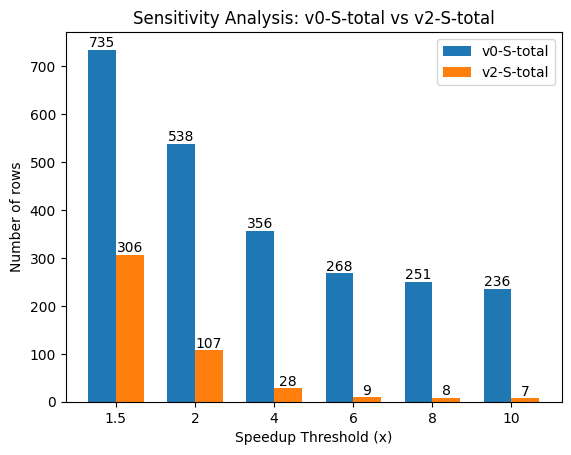

In [ ]:
# =========================
# CONFIG
# =========================

col_a = "v0-S-total"
col_b = "v2-S-total"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.5, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()